# Fashion Assistant — Exploratory Data Analysis (EDA)

## What I'm Building
A **Consumer-to-Shop Clothing Retrieval** system.  
I want to build a system where someone can take a photo of a clothing item they own, and the system finds the matching store listing for it — similar to how Google Lens works but focused on fashion.

## Dataset I'm Using: DeepFashion — Consumer-to-Shop Clothes Retrieval Benchmark
- **Source:** Multimedia Lab, Chinese University of Hong Kong
- **Total images:** 239,557 (195,540 cross-domain consumer↔shop pairs)
- **Restriction:** Non-commercial research and educational use only

### What the dataset looks like on disk
```
Consumer-to-shop Clothes Retrieval Benchmark/
├── img/          ← actual clothing images (both consumer and shop photos)
├── Anno/         ← extra information: bounding boxes, attributes, landmarks
├── Eval/         ← tells me which images are for train, val, and test
└── README.txt    ← documentation I should read first
```

---
## Step 1: Let me first see what's inside the dataset folder

In [2]:
import os
import random
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
from PIL import Image

dataset_path = "/Users/anushrin/Documents/Cowork Playground/FashionRecommendation/workspace/Capstone Fashion Assistant/fashion_assistant/data/DeepFashion Database/Data/Consumer-to-shop Clothes Retrieval Benchmark"

for item in os.listdir(dataset_path):
    print(item)

.DS_Store
img
README.txt
Eval
Anno


**What I see:** Four items — `img/`, `Anno/`, `Eval/`, `README.txt`. This matches what I expected from the dataset description.

---
## Step 2: Reading the README first

Before I touch any data or write any model code, I want to read the README to understand what exactly I'm working with. Key things I learned:
- Images are JPG format, long side resized to 300px, aspect ratio is kept unchanged
- Bounding boxes are available — they tell me where exactly the clothing item is in each image
- Landmark annotations are available — collar, sleeve, hem positions
- Attribute labels are available — things like color, style, fabric (stored as 1=present, -1=absent, 0=unknown)
- There's an evaluation partition file that maps which consumer photo should match which shop photo

In [3]:
with open(os.path.join(dataset_path, "README.txt")) as f:
    print(f.read())

Large-scale Fashion Recognition and Retrieval (DeepFashion) Dataset

Consumer-to-shop Clothes Retrieval Benchmark

--------------------------------------------------------
By Multimedia Lab, The Chinese University of Hong Kong
--------------------------------------------------------

For more information about the dataset, visit the project website:

  http://mmlab.ie.cuhk.edu.hk/projects/DeepFashion.html

If you use the dataset in a publication, please cite the paper below:

  @inproceedings{liu2016deepfashion,
 	author = {Ziwei Liu, Ping Luo, Shi Qiu, Xiaogang Wang, and Xiaoou Tang},
 	title = {DeepFashion: Powering Robust Clothes Recognition and Retrieval with Rich Annotations},
 	booktitle = {Proceedings of IEEE Conference on Computer Vision and Pattern Recognition (CVPR)},
 	month = June,
 	year = {2016} 
  }

Please note that we do not own the copyrights to these images. Their use is RESTRICTED to non-commercial research and educational purposes.



Change Log

Version 1.0, relea

---
## Step 3: Understanding the Evaluation Partition File

This file is the most important one for measuring whether my system works. Here's what I understood:
- Each row tells me: *this consumer photo should match this shop photo* — that's my ground truth
- Every pair is labelled as `train`, `val`, or `test`
- One consumer photo maps to exactly one shop photo
- But one shop photo can be the correct answer for multiple consumer photos (different users photographing the same item)

### Why train/val/test matters for me
- **train** → I'll use this to fine-tune my model later
- **val** → I'll use this to check if the model is improving during training
- **test** → I'll use this only at the end to get my final Recall@K score
- The gallery (shop images I search through) = all shop images from `val + test` combined

My success metric is **Recall@K** — when I give a consumer photo as query, does the correct shop photo appear in my top K results?

In [4]:
eval_path = os.path.join(dataset_path, "Eval", "list_eval_partition.txt")

with open(eval_path) as f:
    lines = f.readlines()

print(f"Total lines: {len(lines)}")
print("\nFirst 5 lines:")
for line in lines[:5]:
    print(line.strip())

Total lines: 195542

First 5 lines:
195540
image_pair_name_1 image_pair_name_2 item_id evaluation_status
img/TOPS/T_Shirt/id_00000001/comsumer_01.jpg       img/TOPS/T_Shirt/id_00000001/shop_02.jpg           id_00000001      test
img/TOPS/T_Shirt/id_00000001/comsumer_02.jpg       img/TOPS/T_Shirt/id_00000001/shop_01.jpg           id_00000001      test
img/TOPS/T_Shirt/id_00000001/comsumer_03.jpg       img/TOPS/T_Shirt/id_00000001/shop_01.jpg           id_00000001      test


In [5]:
# sep=r'\s+' handles variable whitespace; skiprows=1 skips the total count row
df_eval = pd.read_csv(eval_path, sep=r'\s+', skiprows=1)
df_eval.columns = ['consumer_image', 'shop_image', 'item_id', 'split']

print(df_eval.head())
print(f"\nShape: {df_eval.shape}")

                                 consumer_image  \
0  img/TOPS/T_Shirt/id_00000001/comsumer_01.jpg   
1  img/TOPS/T_Shirt/id_00000001/comsumer_02.jpg   
2  img/TOPS/T_Shirt/id_00000001/comsumer_03.jpg   
3  img/TOPS/T_Shirt/id_00000001/comsumer_04.jpg   
4  img/TOPS/T_Shirt/id_00000001/comsumer_05.jpg   

                                 shop_image      item_id split  
0  img/TOPS/T_Shirt/id_00000001/shop_02.jpg  id_00000001  test  
1  img/TOPS/T_Shirt/id_00000001/shop_01.jpg  id_00000001  test  
2  img/TOPS/T_Shirt/id_00000001/shop_01.jpg  id_00000001  test  
3  img/TOPS/T_Shirt/id_00000001/shop_03.jpg  id_00000001  test  
4  img/TOPS/T_Shirt/id_00000001/shop_01.jpg  id_00000001  test  

Shape: (195540, 4)


In [6]:
print(df_eval['split'].value_counts())
print("\nPercentage:")
print(df_eval['split'].value_counts(normalize=True).mul(100).round(1))

split
train    98832
val      48935
test     47773
Name: count, dtype: int64

Percentage:
split
train    50.5
val      25.0
test     24.4
Name: proportion, dtype: float64


### What I found: Split Distribution

| Split | Count | Percentage |
|-------|-------|------------|
| train | 98,832 | 50.5% |
| val   | 48,935 | 25.0% |
| test  | 47,773 | 24.4% |

It's a standard 50/25/25 split. For now I'll focus on the `test` set (47,773 pairs) to evaluate how well a pre-trained model works before I do any training. The training and val splits I'll use later when I start fine-tuning.

---
## Step 4: Building an Image DataFrame

I want to scan the entire `img/` folder and build a table with one row per image, capturing the path, category, item ID, and whether it's a consumer or shop photo.

The folder path already contains all this information:  
`img/<CATEGORY>/<SUBCATEGORY>/<item_id>/<filename>.jpg`

**One surprise I found:** The dataset has a typo in the filenames — `comsumer` instead of `consumer`. I had to account for this in my code.

In [9]:
img_dir = os.path.join(dataset_path, "img")
records = []

for root, dirs, files in os.walk(img_dir):
    #print(root , " " , dirs,  " ", files)
    for fname in files:
        if not fname.endswith(".jpg"):
            continue

        full_path = os.path.join(root, fname)
        rel_path  = os.path.relpath(full_path, dataset_path)

        # parts = ['img', 'TOPS', 'T_Shirt', 'id_00000001', 'comsumer_01.jpg']
        parts = rel_path.split(os.sep)

        category  = parts[1] + "_" + parts[2]                      # e.g. TOPS_T_Shirt
        item_id   = parts[3]                                        # e.g. id_00000001
        img_type  = "consumer" if "comsumer" in fname else "shop"   # handling dataset typo

        records.append({
            "img_path"  : rel_path,
            "category"  : category,
            "item_id"   : item_id,
            "image_type": img_type
        })

print(f"Total records: {len(records)}")
print(f"Sample: {records[0]}")

Total records: 239557
Sample: {'img_path': 'img/TOPS/Summer_Wear/id_00007169/shop_01.jpg', 'category': 'TOPS_Summer_Wear', 'item_id': 'id_00007169', 'image_type': 'shop'}


In [8]:
df_images = pd.DataFrame(records)

print(df_images.shape)
print()
print(df_images.head())
print()
print(df_images['image_type'].value_counts())
print()
print(df_images['category'].value_counts())

(239557, 4)

                                           img_path          category  \
0      img/TOPS/Summer_Wear/id_00007169/shop_01.jpg  TOPS_Summer_Wear   
1  img/TOPS/Summer_Wear/id_00007169/comsumer_01.jpg  TOPS_Summer_Wear   
2  img/TOPS/Summer_Wear/id_00007169/comsumer_02.jpg  TOPS_Summer_Wear   
3  img/TOPS/Summer_Wear/id_00007169/comsumer_03.jpg  TOPS_Summer_Wear   
4      img/TOPS/Summer_Wear/id_00032880/shop_01.jpg  TOPS_Summer_Wear   

       item_id image_type  
0  id_00007169       shop  
1  id_00007169   consumer  
2  id_00007169   consumer  
3  id_00007169   consumer  
4  id_00032880       shop  

image_type
consumer    194165
shop         45392
Name: count, dtype: int64

category
TOPS_Summer_Wear            80299
TOPS_T_Shirt                34847
TROUSERS_Summer_Wear        26545
DRESSES_Dress               18713
TOPS_Coat                   17709
TROUSERS_Pants              14914
TROUSERS_Leggings           10154
TOPS_Lace_Shirt              9093
TOPS_Tank_Top         

### What I found: Image Distribution

| image_type | Count | Percentage |
|------------|-------|------------|
| consumer   | 194,165 | 81% |
| shop       | 45,392  | 19% |

Consumer images outnumber shop images 4:1 — which makes sense because many different users can photograph the same shop item. The top categories are TOPS_Summer_Wear (80K), TOPS_T_Shirt (35K), and TROUSERS_Summer_Wear (27K). The dataset is heavily skewed towards TOPS.

In [10]:
per_item = df_images.groupby(['item_id', 'image_type']).size().unstack(fill_value=0)
per_item.columns = ['consumer_count', 'shop_count']

print("Average images per item:")
print(per_item.mean().round(2))
print()
print("Max images per item:")
print(per_item.max())

Average images per item:
consumer_count    5.73
shop_count        1.34
dtype: float64

Max images per item:
consumer_count    42
shop_count        14
dtype: int64


### What I found: Images Per Item

| Metric | Consumer | Shop |
|--------|----------|------|
| Average | 5.73 | 1.34 |
| Maximum | 42 | 14 |

On average each clothing item has about 6 consumer photos but only 1 shop photo. Someone even photographed the same item 42 times! This confirms the challenge — my model needs to match all those varied consumer photos to just 1-2 clean shop photos.

---
## Step 5: How many images does each clothing item have?

Instead of plotting each item individually (there are thousands), I want to see the distribution — how many items have 1 image, 2 images, and so on. I'm grouping by both `item_id` and `category` together because a unique item is defined by both.

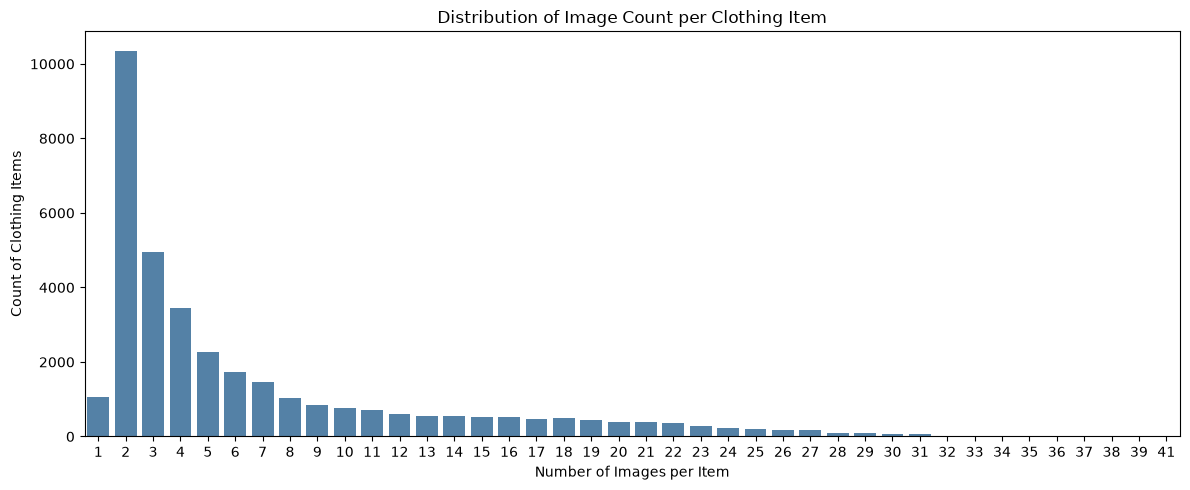

Total unique items : 35425
Avg images per item: 6.76
Most common count  : 2


In [11]:
df_item_counts = df_images.groupby(['item_id', 'category']).size().reset_index(name='image_count')

plt.figure(figsize=(12, 5))
sns.countplot(data=df_item_counts, x='image_count', color='steelblue')
plt.title('Distribution of Image Count per Clothing Item')
plt.xlabel('Number of Images per Item')
plt.ylabel('Count of Clothing Items')
plt.tight_layout()
plt.show()

print(f"Total unique items : {len(df_item_counts)}")
print(f"Avg images per item: {df_item_counts['image_count'].mean():.2f}")
print(f"Most common count  : {df_item_counts['image_count'].mode()[0]}")

### What I found: Long-Tail Distribution

The tallest bar is at 2 — meaning most clothing items (~10,000) have just 2 images total (1 shop + 1 consumer). The count drops sharply after that, with very few items having many photos. This is called a **long-tail distribution** and it's very common in real-world datasets.

This is important for my model — most items have very little data, which means I can't rely on fine-tuning alone. Starting with a strong pre-trained model is the right approach.

---
## Step 6: Looking at the actual images

Before I build any model, I want to look at the images with my own eyes to understand what I'm dealing with.

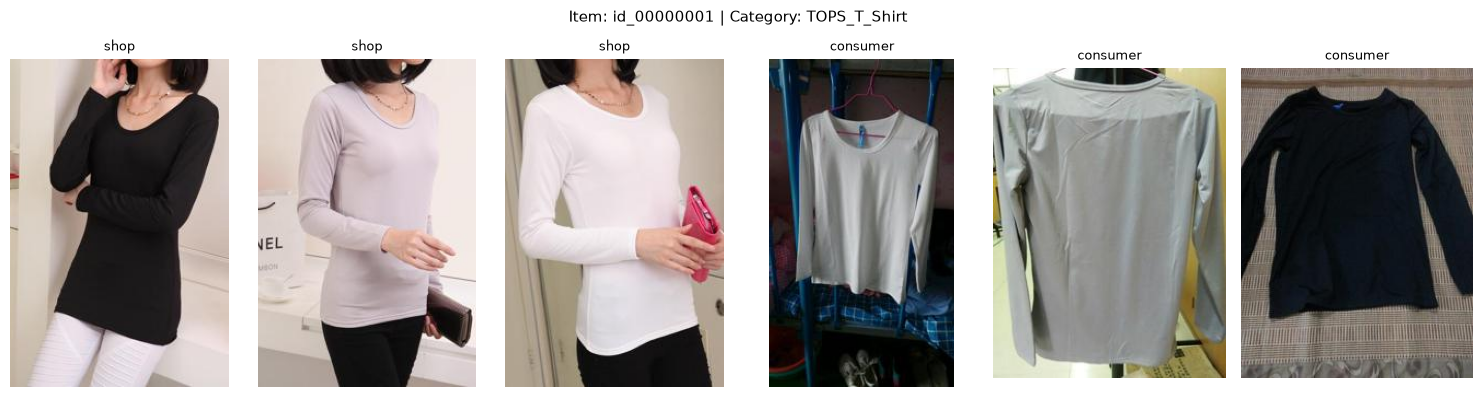

In [12]:
def show_item(item_id, max_images=6):
    """Display all consumer and shop images for a given clothing item."""
    item_imgs = df_images[df_images['item_id'] == item_id]

    fig, axes = plt.subplots(1, min(len(item_imgs), max_images), figsize=(15, 4))
    if len(item_imgs) == 1:
        axes = [axes]

    for ax, (_, row) in zip(axes, item_imgs.iterrows()):
        img = Image.open(os.path.join(dataset_path, row['img_path']))
        ax.imshow(img)
        ax.set_title(row['image_type'], fontsize=9)
        ax.axis('off')

    plt.suptitle(f"Item: {item_id} | Category: {item_imgs.iloc[0]['category']}", fontsize=11)
    plt.tight_layout()
    plt.show()

show_item('id_00000001')

In [ ]:
# Looking at 3 random items to see how consistent the domain gap is
random_items = random.sample(df_images['item_id'].unique().tolist(), 3)
for item_id in random_items:
    show_item(item_id)

### What I observed: The Domain Gap Problem

**Shop photos** look professional — clean background, sharp focus, good lighting, usually on a mannequin or model.  
**Consumer photos** look real-world — blurry, wrinkled, messy backgrounds, different angles, worn on people.

The most striking thing I noticed: **I often can't tell they're the same item just by looking**. The visual difference is large enough that even my eyes struggle. This tells me a simple pixel-comparison algorithm would fail completely here.

The domain gap also varies — some consumer photos are decent quality while others are very degraded. My model needs to handle this full range. This is exactly why I need deep learning — a CNN can learn to match based on deeper patterns like shape, texture, and fabric structure rather than just pixel values.

---
## Step 7: Checking image sizes

I need to know the image size distribution before I pick a preprocessing strategy. CNN models like ResNet need fixed-size square inputs (224×224).

In [13]:
sample = df_images.sample(200, random_state=42)
widths, heights = [], []

for _, row in sample.iterrows():
    img = Image.open(os.path.join(dataset_path, row['img_path']))
    w, h = img.size
    widths.append(w)
    heights.append(h)

print(f"Width  — min: {min(widths)}, max: {max(widths)}, avg: {int(sum(widths)/len(widths))}")
print(f"Height — min: {min(heights)}, max: {max(heights)}, avg: {int(sum(heights)/len(heights))}")

Width  — min: 100, max: 300, avg: 218
Height — min: 100, max: 300, avg: 291


### What I found: Image Dimensions

| Dimension | Min | Max | Avg |
|-----------|-----|-----|-----|
| Width     | 100 | 300 | 218 |
| Height    | 100 | 300 | 291 |

The long side is always ≤ 300px which confirms what the README said. Images are not uniform in size and most are portrait orientation (taller than wide) which makes sense for clothing photos.

Before I feed images into a CNN I'll need to:
1. **Resize** — scale so the short side is at least 224px
2. **Center crop** — take the center 224×224 square
3. **Normalize** — adjust pixel values using ImageNet mean and standard deviation

---
## Step 8: Exploring Bounding Boxes

I wanted to check if using the bounding box annotations to crop images would give my model cleaner input. The bounding box tells me exactly where the clothing item is in the photo using `x1,y1` (top-left corner) and `x2,y2` (bottom-right corner).

In [14]:
bbox_path = os.path.join(dataset_path, "Anno", "list_bbox_consumer2shop.txt")
df_bbox = pd.read_csv(bbox_path, sep=r'\s+', skiprows=2, header=None)
df_bbox.columns = ['img_path', 'clothes_type', 'source_type', 'x1', 'y1', 'x2', 'y2']

print(f"Shape: {df_bbox.shape}")
print(df_bbox.head())

Shape: (239557, 7)
                                            img_path  clothes_type  \
0    img/CLOTHING/Polo_Shirt/id_00006282/shop_01.jpg             1   
1  img/CLOTHING/Polo_Shirt/id_00006282/comsumer_0...             1   
2  img/CLOTHING/Polo_Shirt/id_00006282/comsumer_0...             1   
3  img/CLOTHING/Polo_Shirt/id_00006282/comsumer_0...             1   
4  img/CLOTHING/Polo_Shirt/id_00006282/comsumer_0...             1   

   source_type  x1  y1   x2   y2  
0            1   1  39  200  292  
1            2   1   1  223  300  
2            2   1   1  169  230  
3            2   6   8  215  300  
4            2   1   1  225  300  


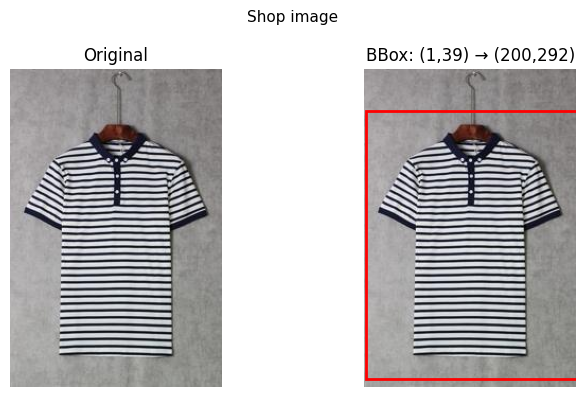

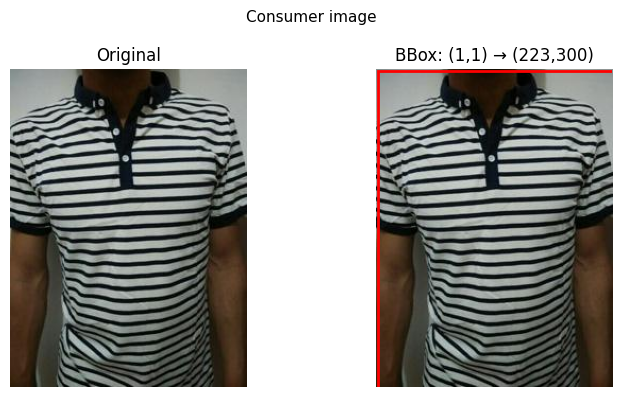

In [17]:
def show_with_bbox(img_path):
    """Display image side-by-side with its bounding box drawn in red."""
    row = df_bbox[df_bbox['img_path'] == img_path].iloc[0]
    img = Image.open(os.path.join(dataset_path, img_path))

    fig, axes = plt.subplots(1, 2, figsize=(8, 4))

    axes[0].imshow(img)
    axes[0].set_title("Original")
    axes[0].axis('off')

    axes[1].imshow(img)
    rect = patches.Rectangle(
        (row['x1'], row['y1']),
        row['x2'] - row['x1'],   # width
        row['y2'] - row['y1'],   # height
        linewidth=2, edgecolor='red', facecolor='none'
    )
    axes[1].add_patch(rect)
    axes[1].set_title(f"BBox: ({row['x1']},{row['y1']}) → ({row['x2']},{row['y2']})")
    axes[1].axis('off')

    img_type = 'Shop' if row['source_type'] == 1 else 'Consumer'
    plt.suptitle(f"{img_type} image", fontsize=11)
    plt.tight_layout()
    plt.show()

show_with_bbox("img/CLOTHING/Polo_Shirt/id_00006282/shop_01.jpg")
show_with_bbox("img/CLOTHING/Polo_Shirt/id_00006282/comsumer_01.jpg")

### What I decided: Skip bbox cropping for now

After looking at several images with bounding boxes drawn, I noticed the boxes are inconsistent — some cut off part of the clothing, others have too much background included. The annotations aren't reliable enough to use for cropping.

Since the images are already reasonably tight around the clothing items, I'll use the full images for my baseline model. Cropping with noisy bounding boxes could hurt more than it helps.

I'll revisit this later as a creativity experiment — compare Recall@K with and without bbox cropping to see if there's a real difference.

---
## Step 9: Exploring Clothing Attributes

The dataset has 303 clothing attributes organized into 18 types. I want to understand what's available because this could power a multi-modal search feature later — where someone can search by image AND text description.

In [ ]:
attr_path      = os.path.join(dataset_path, "Anno", "list_attr_cloth.txt")
attr_type_path = os.path.join(dataset_path, "Anno", "list_attr_type.txt")

df_attr = pd.read_csv(attr_path, sep=r'\s{2,}', skiprows=2, header=None, engine='python')
df_attr.columns = ['attr_chinese', 'attr_english', 'attr_type']

df_attr_types = pd.read_csv(attr_type_path, sep=r'\s{2,}', skiprows=2, header=None, engine='python')
df_attr_types.columns = ['type_chinese', 'type_english']
df_attr_types.index = range(1, len(df_attr_types) + 1)

print(f"Total attributes: {len(df_attr)}")
print("\nAttribute types:")
for i, row in df_attr_types.iterrows():
    count = len(df_attr[df_attr['attr_type'] == i])
    print(f"  Type {i:2d} — {row['type_english']:<40} ({count} attributes)")

In [ ]:
# Visualizing how many attributes each type has
attr_counts = df_attr['attr_type'].value_counts().sort_index()
type_labels = df_attr_types['type_english'].tolist()

plt.figure(figsize=(12, 5))
plt.bar(type_labels, attr_counts.values, color='steelblue')
plt.xticks(rotation=45, ha='right')
plt.title('Number of Attributes per Type')
plt.ylabel('Attribute Count')
plt.tight_layout()
plt.show()

### What I found: Attribute Distribution

The dataset has the most attributes for **part details of clothes** (77 attributes) — very specific descriptions of pockets, embellishments, zippers, decorations etc. The fewest are for **type of clothes buttons** (7 attributes) which makes sense since there aren't many button styles.

What this tells me is that the dataset is richest in **fine-grained visual details** rather than broad categories. Instead of just saying "this is a T-shirt", it can describe exactly how the T-shirt is constructed — collar type, sleeve design, pocket style, fabric etc.

For now I won't use attributes in my baseline model — I'll rely purely on image similarity. But later I could combine image embeddings with attribute text to build a more powerful multi-modal search.

---
## My EDA Summary — Key Takeaways

| What I found | What it means for my model |
|---------|----------------------|
| 239,557 total images | I'll need batch processing — can't load all at once |
| 81% consumer, 19% shop | Many query variations per item to handle |
| Most items have only 2 images | Fine-tuning on sparse data is hard — need a strong pre-trained model |
| Large domain gap between consumer and shop | Simple pixel matching won't work — I need deep learning |
| Domain gap varies across items | My model needs to be robust to different photo qualities |
| Images range from 100–300px | I need to resize and center crop to 224×224 before the CNN |
| Bounding boxes are imperfect | I'll skip bbox cropping for the baseline |
| 303 attributes covering fine-grained details | Good foundation for multi-modal search later |
| 50/25/25 train/val/test split | I'll use the test set to measure my baseline Recall@K |

**What's next:** Model selection — I need to decide which CNN backbone to use and why.